<a href="https://colab.research.google.com/github/wadeea23/Facial-Emotion-Recognition.lab/blob/main/wadeea_lab_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


**part 1**

In [85]:
zip_path="/content/labNN.zip"
extract_path="/content/labNN"
with zipfile.ZipFile(zip_path,"r") as zip_ref:
  zip_ref.extractall(extract_path)
print(os.listdir(extract_path))

['train', 'test']


In [86]:
train_path = os.path.join(extract_path, "train")
test_path = os.path.join(extract_path, "test")
print(os.listdir(train_path))
print(os.listdir(test_path))

['neutral', 'surprise', 'angry', 'happy', 'disgust', 'sad', 'fear']
['neutral', 'surprise', 'angry', 'happy', 'disgust', 'sad', 'fear']


In [87]:
emotions = os.listdir(train_path) ## to known every feeling how many pic in thair
for i in emotions:
    print(i, len(os.listdir(os.path.join(train_path, i))))

neutral 4965
surprise 3171
angry 3995
happy 7215
disgust 436
sad 4830
fear 4097


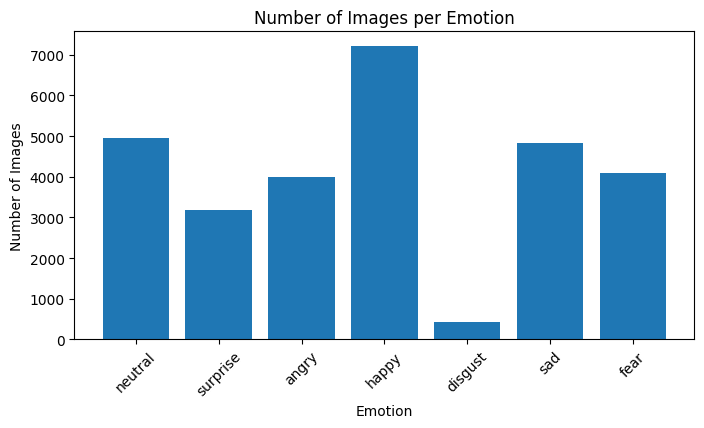

In [88]:
plt.figure(figsize=(8, 4))
plt.bar(emotions, [
    len(os.listdir(os.path.join(train_path, i)))
    for i in emotions])

plt.title("Number of Images per Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [89]:
x_train, x_test, y_train, y_test = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [90]:
x_train = [] ## preprocessing & understand data to read the data for step 2
y_train = []

for i in os.listdir(train_path):
    for j in os.listdir(os.path.join(train_path, i)):
        img = Image.open(os.path.join(train_path, i, j)).convert("L")
        x_train.append(np.array(img))
        y_train.append(i)

x_train = np.array(x_train)
y_train = np.array(y_train)

print(x_train.shape)
print(y_train.shape)
print('img_dim',x_train.shape[1:])

(28709, 48, 48)
(28709,)
img_dim (48, 48)


In [91]:
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_train = to_categorical(y_train)
print(y_train.shape)

(28709, 7)


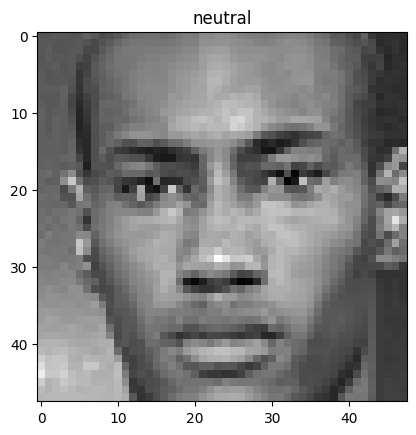

In [92]:
plt.imshow(x_train[0], cmap='gray')
plt.title(le.classes_[np.argmax(y_train[0])])
plt.show()

In [93]:
x_train = x_train / 255

**PART 2**
Neural Network

In [94]:
model = Sequential()
model.add(Input(shape=(48, 48)))
model.add(Flatten())
model.add(Dense(128))
model.add(Activation('relu'))
model.add(Dense(7))
model.add(Activation('softmax'))


In [95]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           903 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 7)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,943 (1.13 MB)

 Trainable params: 295,943 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

In [96]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [97]:
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.3652 - loss: 1.5801 - val_accuracy: 0.0246 - val_loss: 6.9216
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4043 - loss: 1.4882 - val_accuracy: 0.0204 - val_loss: 10.2657
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.4168 - loss: 1.4640 - val_accuracy: 5.2247e-04 - val_loss: 11.9104
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.4299 - loss: 1.4393 - val_accuracy: 0.0540 - val_loss: 10.8384
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4389 - loss: 1.4218 - val_accuracy: 0.0300 - val_loss: 10.1751
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4359 - loss: 1.4172 - val_accuracy: 0.0402 - val_loss: 10.1925
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4444 - loss: 1.4063 - val_accuracy: 0.0181 - val_loss: 17.9381
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4503 - loss: 1.3894 - val

<Axes: >

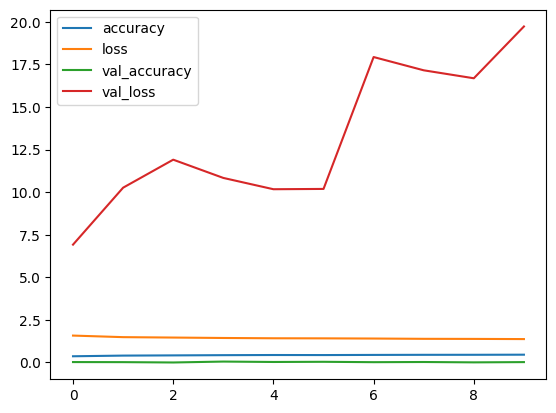

In [98]:
pd.DataFrame(history.history).plot()

In [99]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3694 - loss: 5.0050
Test Accuracy: 0.36938348412513733
Test Loss: 5.0050129890441895


In [100]:
y_pred = model.predict(x_test)
y_pred = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [101]:
accuracy_score(y_true, y_pred)

0.36938349007314525

In [102]:
classification_report(y_true, y_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


'              precision    recall  f1-score   support\n\n           0       0.37      0.14      0.21       799\n           1       0.00      0.00      0.00        87\n           2       0.00      0.00      0.00       820\n           3       0.46      0.67      0.55      1443\n           4       0.26      0.67      0.38       993\n           5       0.36      0.09      0.14       966\n           6       0.51      0.47      0.49       634\n\n    accuracy                           0.37      5742\n   macro avg       0.28      0.29      0.25      5742\nweighted avg       0.33      0.37      0.31      5742\n'

In [103]:
confusion_matrix(y_true, y_pred)

array([[114,   0,   0, 244, 355,  35,  51],
       [  6,   0,   0,  23,  47,   1,  10],
       [ 47,   0,   0, 249, 386,  40,  98],
       [ 31,   0,   0, 960, 359,  40,  53],
       [ 37,   0,   0, 228, 665,  34,  29],
       [ 68,   0,   0, 254, 514,  87,  43],
       [  9,   0,   0, 117, 208,   5, 295]])

**part 3 **

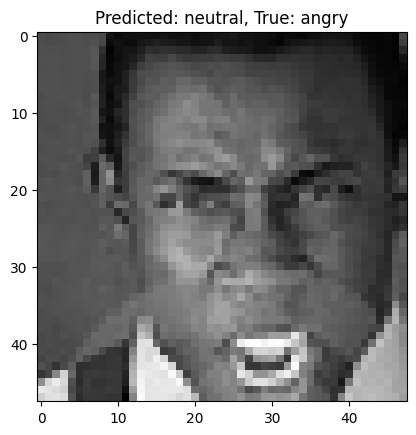

In [104]:
errors = np.where(y_pred != y_true)
for i in errors[0]:
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Predicted: {le.classes_[y_pred[i]]}, True: {le.classes_[y_true[i]]}")

The model made mistakes because some emotions look similar. Some images may also be unclear or have different lighting.

In [105]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [106]:
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4617 - loss: 1.3679 - val_accuracy: 0.0385 - val_loss: 16.2937
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.4624 - loss: 1.3621 - val_accuracy: 0.0143 - val_loss: 25.7529
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4652 - loss: 1.3557 - val_accuracy: 0.0308 - val_loss: 20.3324
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4688 - loss: 1.3479 - val_accuracy: 0.0181 - val_loss: 26.8134
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4699 - loss: 1.3397 - val_accuracy: 0.0803 - val_loss: 21.0828
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.4718 - loss: 1.3398 - val_accuracy: 0.0268 - val_loss: 25.2540


In [107]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3750 - loss: 4.3087
Test Accuracy: 0.3749564588069916
Test Loss: 4.308681964874268


**part 4**

In [108]:
%%writefile /content/app.py
model.save("emotion_model.keras")
with open("emotion_classes.json", "w") as f:
    json.dump(le.classes_.tolist(), f)

files.download("emotion_model.keras")
files.download("emotion_classes.json")


Overwriting /content/app.py


In [109]:
!pip install streamlit pyngrok

In [116]:
%%writefile /content/app.py
import streamlit as st
import numpy as np
import pickle
from PIL import Image
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model("/content/emotion_model.keras")

# Load emotion names
with open("/content/emotion_classes.pkl", "rb") as f:
    classes = pickle.load(f)

# App title
st.title("Facial Emotion Detector")
st.write("Upload an image or take a photo to predict the emotion.")

# Select image
uploaded_image = st.file_uploader(
    "Upload an Image",
    type=["jpg", "jpeg", "png"]
)

camera_image = st.camera_input("Or Take a Photo")

if uploaded_image is not None:
    image_file = uploaded_image
else:
    image_file = camera_image

# Display and predict
if image_file is not None:

    image = Image.open(image_file)
    st.image(image, caption="Your Image", width=300)

    if st.button("Predict Emotion"):

        # Prepare image
        image = image.convert("L")
        image = image.resize((48, 48))

        image = np.array(image) / 255.0
        image = np.expand_dims(image, axis=0)

        # Predict
        prediction = model.predict(image, verbose=0)[0]
        best_index = np.argmax(prediction)

        # Show result
        st.subheader("Predicted Emotion")
        st.success(classes[best_index].capitalize())

        # Show probabilities
        st.subheader("Emotion Probabilities")

        for i in range(len(classes)):
            st.write(classes[i].capitalize())
            st.progress(float(prediction[i]))
            st.write(f"{prediction[i] * 100:.2f}%")





Overwriting /content/app.py


In [117]:
!streamlit run /content/app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > /content/log.txt 2>&1 &

In [118]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>